# Statlog (Heart) Dataset: Preprocessing & Comprehensive Feature Visualization

This notebook provides an end-to-end **data preprocessing and feature-by-feature exploratory analysis** for the **Statlog (Heart)** dataset from the UCI Machine Learning Repository.

### Key Highlights:
1. **Header & Schema Rectification:** In previous notebooks, loading without `header=None` caused the first sample to become column names (leaving 269 instead of 270 records). Here, the full 270 records are parsed with standard clinical feature names.
2. **Target Binarization:** Converting the target variable (`1 = Absence`, `2 = Presence`) to standard machine learning convention (`0 = Healthy`, `1 = Heart Disease`).
3. **Feature-by-Feature Statistical Analysis & Visualization:** In-depth univariate and bivariate plots (histograms, KDEs, boxplots, stacked bar charts) along with hypothesis testing ($t$-test and $\chi^2$ tests) for all 13 predictors.
4. **Correlation Analysis:** Full correlation heatmap with clinically relevant correlation insights.
5. **Zero-Leakage Preprocessing Pipeline:** Stratified splitting prior to transformations, One-Hot Encoding, Min-Max / Standard Scaling, and training-only SMOTE balancing.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from imblearn.over_sampling import SMOTE

# Plotting configuration
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.autolayout'] = True

## 1. Data Ingestion & Schema Definition

The Statlog dataset contains 13 clinical attributes and 1 target attribute recorded across 270 patient observations. The file `heart.dat` is space-delimited without a header row.

In [2]:
# Standard clinical attribute names matching medical literature
COLUMNS = [
    'age',                  # 1. Age in years (Real)
    'sex',                  # 2. Sex: 1 = Male, 0 = Female (Binary)
    'chest_pain_type',      # 3. Chest pain type (Nominal: 1: typ. angina, 2: atyp. angina, 3: non-anginal, 4: asympt.)
    'resting_bp',           # 4. Resting blood pressure in mm Hg (Real)
    'serum_chol',           # 5. Serum cholesterol in mg/dl (Real)
    'fasting_blood_sugar',  # 6. Fasting blood sugar > 120 mg/dl: 1 = true, 0 = false (Binary)
    'resting_ecg',          # 7. Resting ECG (Nominal: 0: normal, 1: ST-T wave abn, 2: LV hypertrophy)
    'max_heart_rate',       # 8. Maximum heart rate achieved (Real)
    'exercise_angina',      # 9. Exercise induced angina: 1 = yes, 0 = no (Binary)
    'oldpeak',              # 10. ST depression induced by exercise relative to rest (Real)
    'slope',                # 11. Slope of peak exercise ST segment (Ordered: 1: upsloping, 2: flat, 3: downsloping)
    'major_vessels',        # 12. Number of major vessels (0-3) colored by fluoroscopy (Real/Count)
    'thal',                 # 13. Thallium scan: 3 = normal, 6 = fixed defect, 7 = reversible defect (Nominal)
    'target'                # 14. Target: 1 = Absence, 2 = Presence
]

# Load space-delimited heart.dat file
data_path = 'datasets/statlog+heart/heart.dat'
df = pd.read_csv(data_path, sep=r'\s+', header=None, names=COLUMNS)

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Dataset Shape: 270 rows, 14 columns


,age,sex,chest_pain_type,resting_bp,serum_chol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_angina,oldpeak,slope,major_vessels,thal,target
0,70.0,1.0,4.0,130.0,322.0,0.0,2.0,109.0,0.0,2.4,2.0,3.0,3.0,2
1,67.0,0.0,3.0,115.0,564.0,0.0,2.0,160.0,0.0,1.6,2.0,0.0,7.0,1
2,57.0,1.0,2.0,124.0,261.0,0.0,0.0,141.0,0.0,0.3,1.0,0.0,7.0,2
3,64.0,1.0,4.0,128.0,263.0,0.0,0.0,105.0,1.0,0.2,2.0,1.0,7.0,1
4,74.0,0.0,2.0,120.0,269.0,0.0,2.0,121.0,1.0,0.2,1.0,1.0,3.0,1


## 2. Target Variable Binarization & Integrity Checks

In `heart.dat`:
* `1` denotes **Absence of Heart Disease** (Healthy)
* `2` denotes **Presence of Heart Disease** (CVD)

We map `1 -> 0` (Healthy) and `2 -> 1` (Heart Disease).

Missing Values across all columns:
age                    0
sex                    0
chest_pain_type        0
resting_bp             0
serum_chol             0
fasting_blood_sugar    0
resting_ecg            0
max_heart_rate         0
exercise_angina        0
oldpeak                0
slope                  0
major_vessels          0
thal                   0
target                 0
dtype: int64

Class Balance:
Healthy (0): 150 (55.56%)
Heart Disease (1): 120 (44.44%)


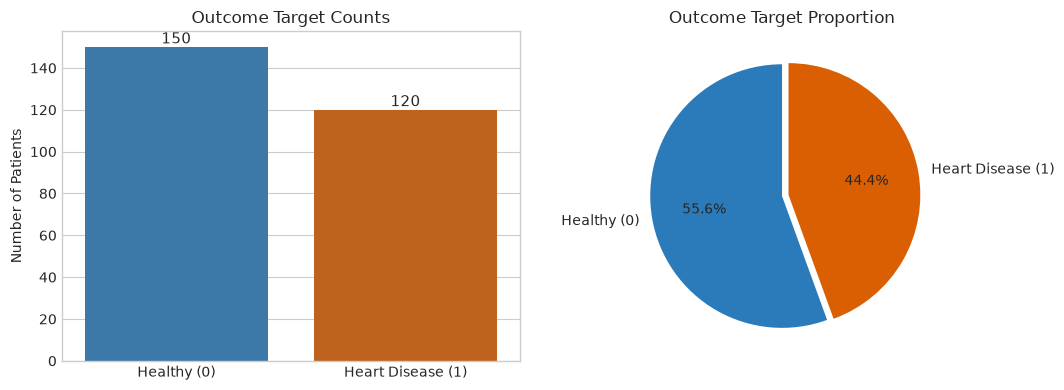

In [3]:
# Map target to standard 0/1 binary values
df['target'] = df['target'].map({1: 0, 2: 1})

print("Missing Values across all columns:")
print(df.isna().sum())

counts = df['target'].value_counts()
pcts = df['target'].value_counts(normalize=True) * 100
print(f"\nClass Balance:\nHealthy (0): {counts[0]} ({pcts[0]:.2f}%)\nHeart Disease (1): {counts[1]} ({pcts[1]:.2f}%)")

# Plot Target Distribution
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x=['Healthy (0)', 'Heart Disease (1)'], y=counts.values, hue=['Healthy (0)', 'Heart Disease (1)'], palette=['#2b7bba', '#d95f02'], legend=False, ax=axes[0])
axes[0].set_title('Outcome Target Counts', fontsize=12)
axes[0].set_ylabel('Number of Patients')
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom', fontsize=11)

axes[1].pie(counts.values, labels=['Healthy (0)', 'Heart Disease (1)'], autopct='%1.1f%%', colors=['#2b7bba', '#d95f02'], startangle=90, explode=[0, 0.05])
axes[1].set_title('Outcome Target Proportion', fontsize=12)
plt.tight_layout()
plt.show()

## 3. Dataset Summary Statistics
Inspect the 5-number summary and distributions of all features.

In [4]:
summary_stats = df.describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
summary_stats['IQR'] = summary_stats['75%'] - summary_stats['25%']
summary_stats['Skewness'] = df.skew()
display(summary_stats.round(2))

,mean,std,min,25%,50%,75%,max,IQR,Skewness
age,54.43,9.11,29.0,48.0,55.0,61.0,77.0,13.0,-0.16
sex,0.68,0.47,0.0,0.0,1.0,1.0,1.0,1.0,-0.77
chest_pain_type,3.17,0.95,1.0,3.0,3.0,4.0,4.0,1.0,-0.88
resting_bp,131.34,17.86,94.0,120.0,130.0,140.0,200.0,20.0,0.72
serum_chol,249.66,51.69,126.0,213.0,245.0,280.0,564.0,67.0,1.18
fasting_blood_sugar,0.15,0.36,0.0,0.0,0.0,0.0,1.0,0.0,1.99
resting_ecg,1.02,1.00,0.0,0.0,2.0,2.0,2.0,2.0,-0.04
max_heart_rate,149.68,23.17,71.0,133.0,153.5,166.0,202.0,33.0,-0.53
exercise_angina,0.33,0.47,0.0,0.0,0.0,1.0,1.0,1.0,0.73
oldpeak,1.05,1.15,0.0,0.0,0.8,1.6,6.2,1.6,1.26


## 4. Feature-by-Feature In-Depth Visualizations & Statistical Tests

We split the 13 clinical predictors into:
1. **Numerical / Continuous Features:** `age`, `resting_bp`, `serum_chol`, `max_heart_rate`, `oldpeak`, `major_vessels`
2. **Categorical & Binary Features:** `sex`, `chest_pain_type`, `fasting_blood_sugar`, `resting_ecg`, `exercise_angina`, `slope`, `thal`

For each feature, we analyze the distribution and evaluate the statistical difference between Healthy patients and Heart Disease patients using **Welch's two-sample $t$-test** (for continuous) and **Pearson's $\chi^2$ test of independence** (for categorical).

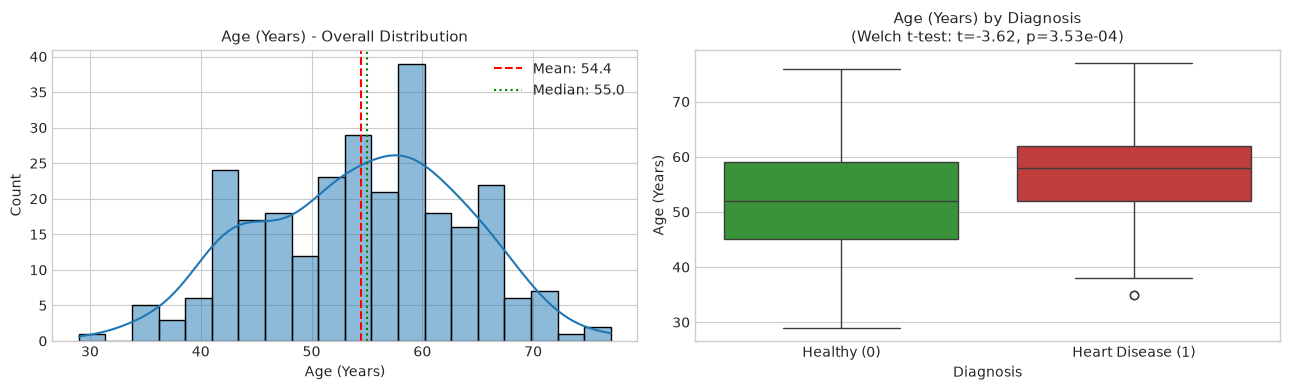

-> age: Healthy Mean = 52.71 ± 9.51 | CVD Mean = 56.59 ± 8.12 [Statistically Significant (p < 0.05)]
--------------------------------------------------------------------------------


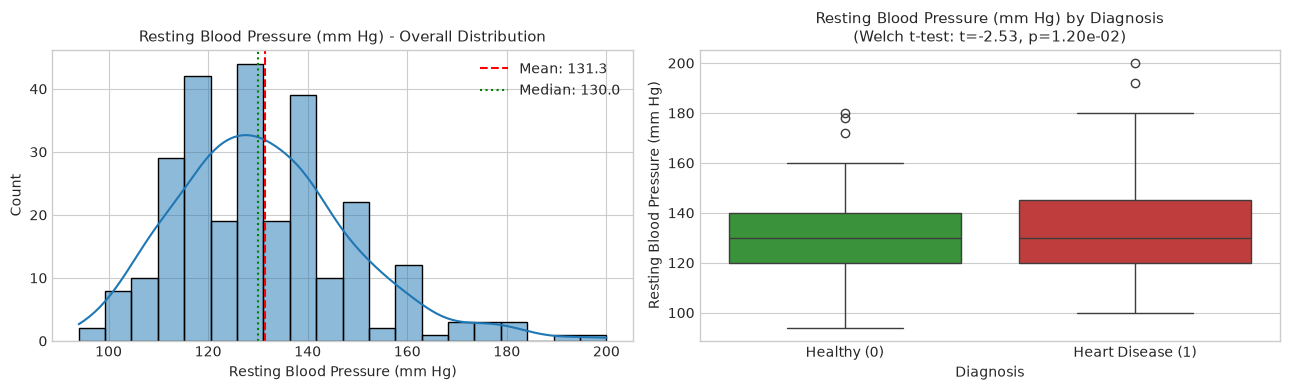

-> resting_bp: Healthy Mean = 128.87 ± 16.46 | CVD Mean = 134.44 ± 19.10 [Statistically Significant (p < 0.05)]
--------------------------------------------------------------------------------


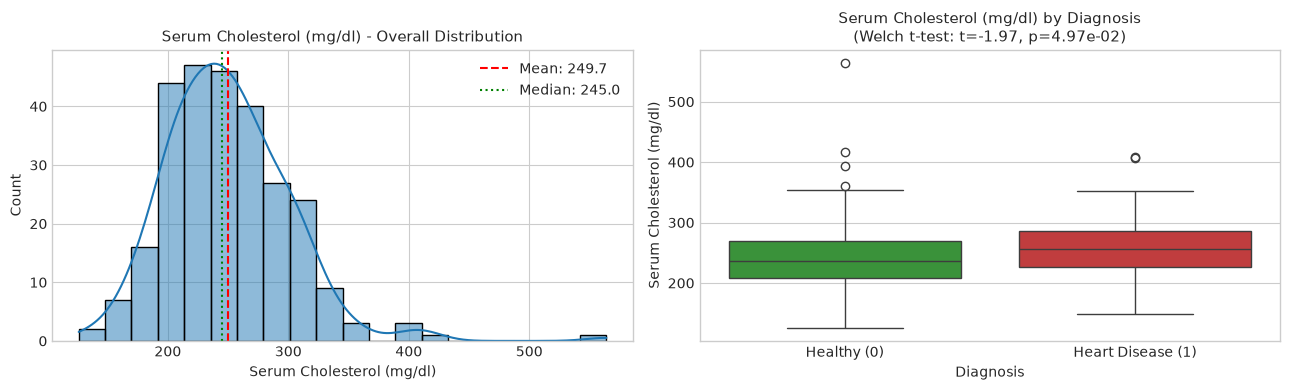

-> serum_chol: Healthy Mean = 244.21 ± 54.02 | CVD Mean = 256.47 ± 47.97 [Statistically Significant (p < 0.05)]
--------------------------------------------------------------------------------


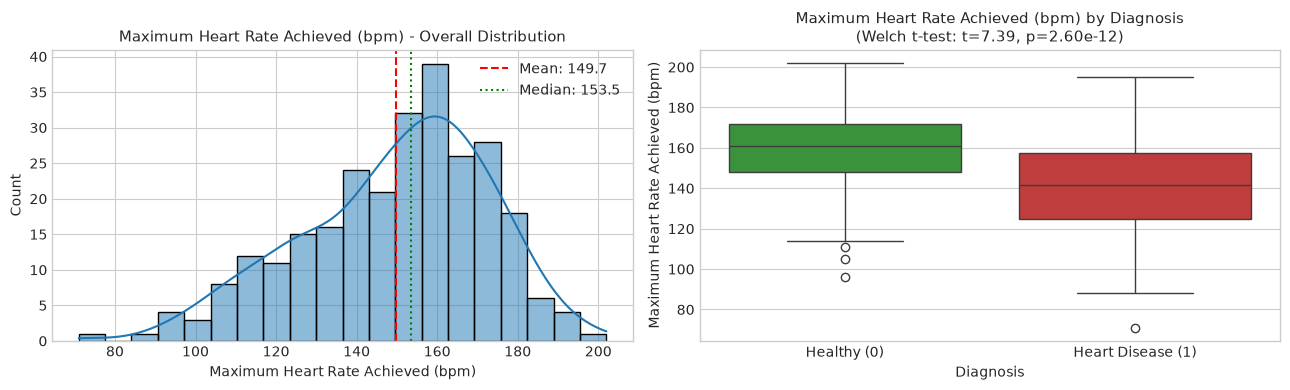

-> max_heart_rate: Healthy Mean = 158.33 ± 19.28 | CVD Mean = 138.86 ± 23.13 [Statistically Significant (p < 0.05)]
--------------------------------------------------------------------------------


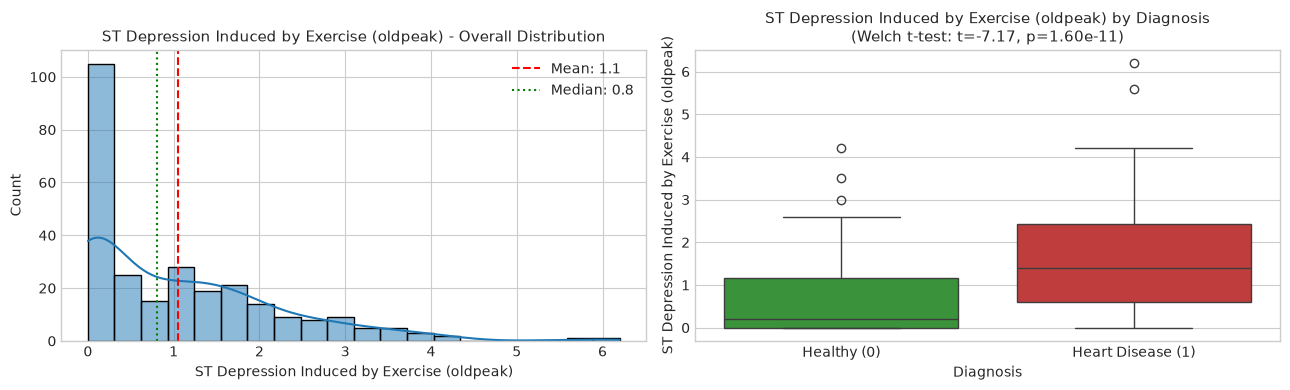

-> oldpeak: Healthy Mean = 0.62 ± 0.80 | CVD Mean = 1.58 ± 1.28 [Statistically Significant (p < 0.05)]
--------------------------------------------------------------------------------


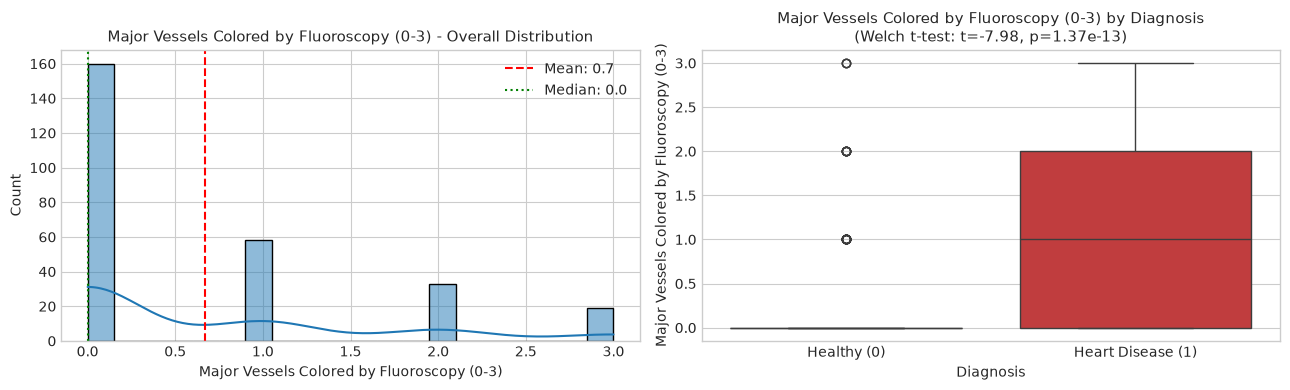

-> major_vessels: Healthy Mean = 0.29 ± 0.65 | CVD Mean = 1.15 ± 1.03 [Statistically Significant (p < 0.05)]
--------------------------------------------------------------------------------


In [5]:
num_features = [
    ('age', 'Age (Years)'),
    ('resting_bp', 'Resting Blood Pressure (mm Hg)'),
    ('serum_chol', 'Serum Cholesterol (mg/dl)'),
    ('max_heart_rate', 'Maximum Heart Rate Achieved (bpm)'),
    ('oldpeak', 'ST Depression Induced by Exercise (oldpeak)'),
    ('major_vessels', 'Major Vessels Colored by Fluoroscopy (0-3)')
]

for col, title in num_features:
    healthy_vals = df[df['target'] == 0][col]
    cvd_vals = df[df['target'] == 1][col]
    t_stat, p_val = stats.ttest_ind(healthy_vals, cvd_vals, equal_var=False)
    
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    
    # Subplot 1: Distribution histogram + KDE
    sns.histplot(df[col], kde=True, ax=axes[0], color='#1f77b4', bins=20)
    axes[0].axvline(df[col].mean(), color='red', linestyle='--', label=f"Mean: {df[col].mean():.1f}")
    axes[0].axvline(df[col].median(), color='green', linestyle=':', label=f"Median: {df[col].median():.1f}")
    axes[0].set_title(f"{title} - Overall Distribution", fontsize=11)
    axes[0].set_xlabel(title)
    axes[0].legend()
    
    # Subplot 2: Comparison by CVD status
    sns.boxplot(x='target', y=col, data=df, ax=axes[1], hue='target', palette=['#2ca02c', '#d62728'], legend=False)
    axes[1].set_xticks([0, 1])
    axes[1].set_xticklabels(['Healthy (0)', 'Heart Disease (1)'])
    axes[1].set_title(f"{title} by Diagnosis\n(Welch t-test: t={t_stat:.2f}, p={p_val:.2e})", fontsize=11)
    axes[1].set_xlabel('Diagnosis')
    axes[1].set_ylabel(title)
    
    plt.tight_layout()
    plt.show()
    
    sig_text = "Statistically Significant (p < 0.05)" if p_val < 0.05 else "Not Statistically Significant (p >= 0.05)"
    print(f"-> {col}: Healthy Mean = {healthy_vals.mean():.2f} ± {healthy_vals.std():.2f} | CVD Mean = {cvd_vals.mean():.2f} ± {cvd_vals.std():.2f} [{sig_text}]")
    print("-" * 80)

### Categorical & Binary Features Analysis

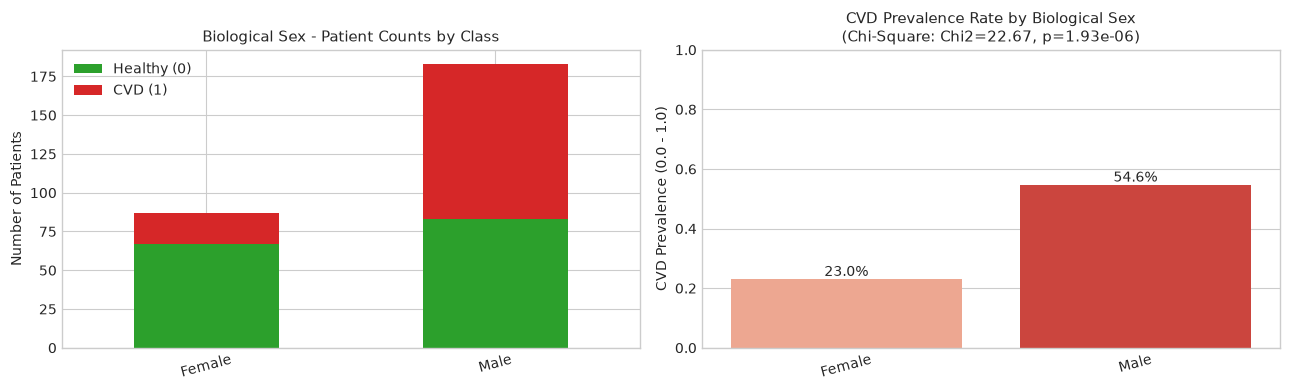

-> sex Disease Rates: Female: 23.0%, Male: 54.6%
--------------------------------------------------------------------------------


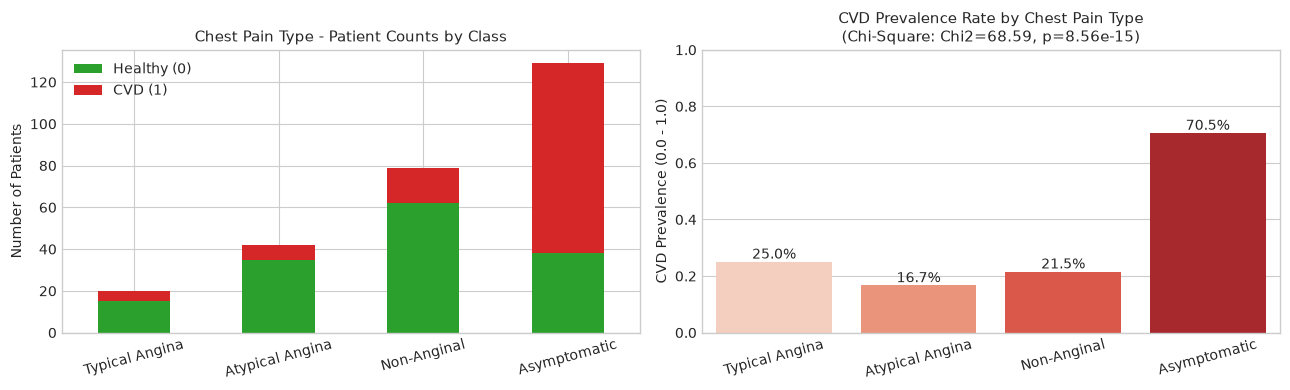

-> chest_pain_type Disease Rates: Typical Angina: 25.0%, Atypical Angina: 16.7%, Non-Anginal: 21.5%, Asymptomatic: 70.5%
--------------------------------------------------------------------------------


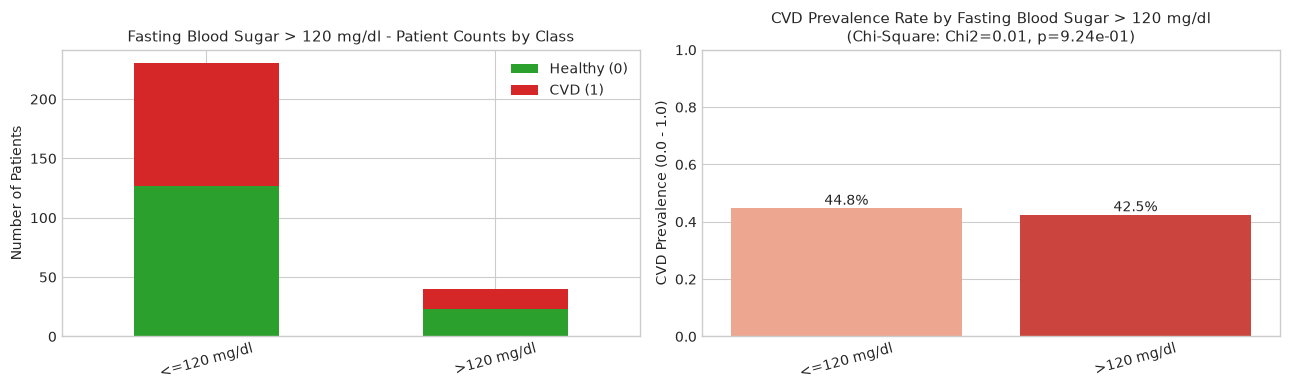

-> fasting_blood_sugar Disease Rates: <=120 mg/dl: 44.8%, >120 mg/dl: 42.5%
--------------------------------------------------------------------------------


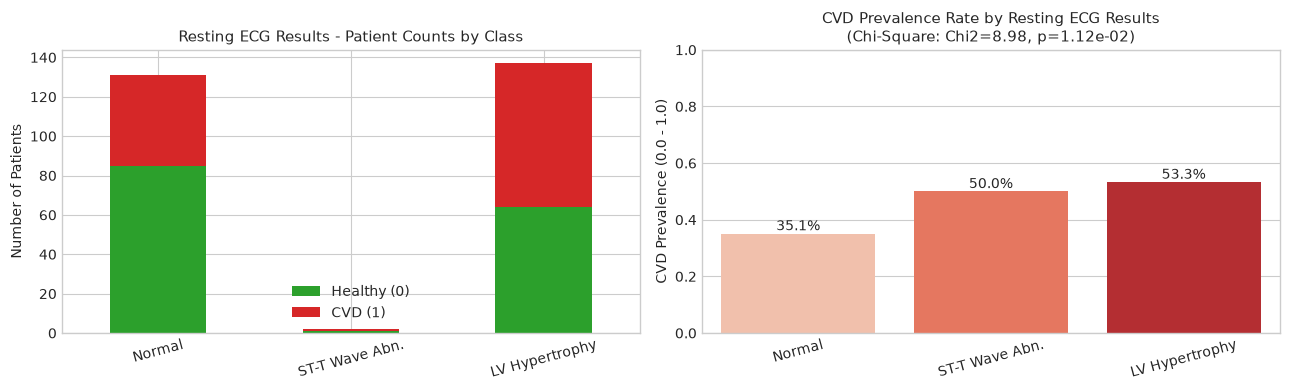

-> resting_ecg Disease Rates: Normal: 35.1%, ST-T Wave Abn.: 50.0%, LV Hypertrophy: 53.3%
--------------------------------------------------------------------------------


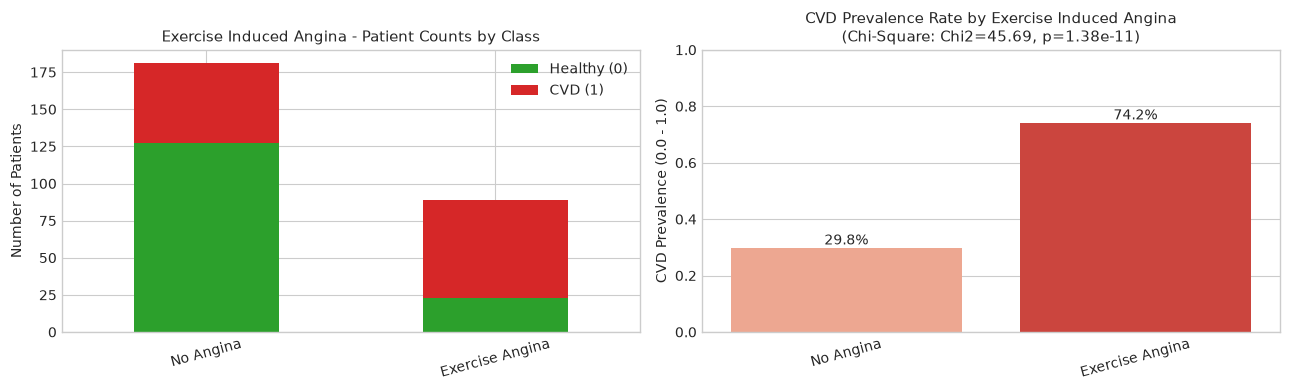

-> exercise_angina Disease Rates: No Angina: 29.8%, Exercise Angina: 74.2%
--------------------------------------------------------------------------------


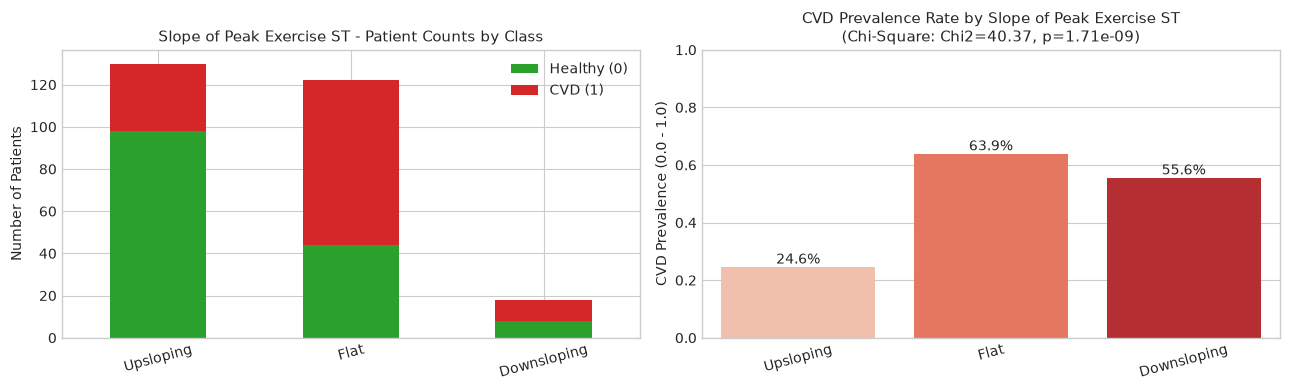

-> slope Disease Rates: Upsloping: 24.6%, Flat: 63.9%, Downsloping: 55.6%
--------------------------------------------------------------------------------


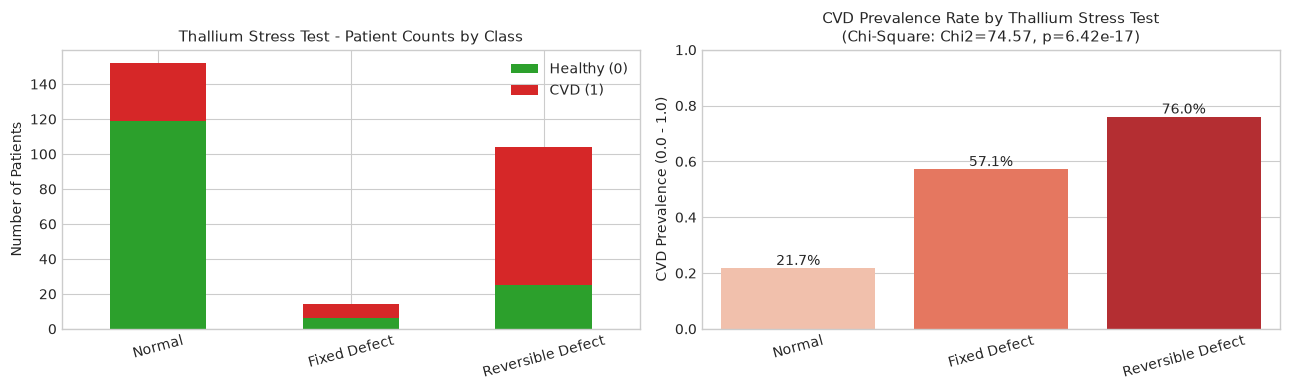

-> thal Disease Rates: Normal: 21.7%, Fixed Defect: 57.1%, Reversible Defect: 76.0%
--------------------------------------------------------------------------------


In [6]:
cat_features = [
    ('sex', 'Biological Sex', {0: 'Female', 1: 'Male'}),
    ('chest_pain_type', 'Chest Pain Type', {1: 'Typical Angina', 2: 'Atypical Angina', 3: 'Non-Anginal', 4: 'Asymptomatic'}),
    ('fasting_blood_sugar', 'Fasting Blood Sugar > 120 mg/dl', {0: '<=120 mg/dl', 1: '>120 mg/dl'}),
    ('resting_ecg', 'Resting ECG Results', {0: 'Normal', 1: 'ST-T Wave Abn.', 2: 'LV Hypertrophy'}),
    ('exercise_angina', 'Exercise Induced Angina', {0: 'No Angina', 1: 'Exercise Angina'}),
    ('slope', 'Slope of Peak Exercise ST', {1: 'Upsloping', 2: 'Flat', 3: 'Downsloping'}),
    ('thal', 'Thallium Stress Test', {3: 'Normal', 6: 'Fixed Defect', 7: 'Reversible Defect'})
]

for col, title, label_dict in cat_features:
    contingency = pd.crosstab(df[col], df['target'])
    chi2, p_val, _, _ = stats.chi2_contingency(contingency)
    
    # Calculate disease prevalence (% CVD) per category
    rates_df = df.groupby(col)['target'].agg(['count', 'mean']).reset_index()
    rates_df['label'] = rates_df[col].map(label_dict)
    
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    
    # Subplot 1: Stacked Counts
    stacked_counts = df.groupby([col, 'target']).size().unstack(fill_value=0)
    stacked_counts.index = stacked_counts.index.map(label_dict)
    stacked_counts.plot(kind='bar', stacked=True, color=['#2ca02c', '#d62728'], ax=axes[0])
    axes[0].set_title(f"{title} - Patient Counts by Class", fontsize=11)
    axes[0].set_xlabel('')
    axes[0].set_ylabel('Number of Patients')
    axes[0].legend(['Healthy (0)', 'CVD (1)'])
    axes[0].tick_params(axis='x', rotation=15)
    
    # Subplot 2: Prevalence Rate %
    sns.barplot(x='label', y='mean', data=rates_df, hue='label', palette='Reds', legend=False, ax=axes[1])
    axes[1].set_title(f"CVD Prevalence Rate by {title}\n(Chi-Square: Chi2={chi2:.2f}, p={p_val:.2e})", fontsize=11)
    axes[1].set_xlabel('')
    axes[1].set_ylabel('CVD Prevalence (0.0 - 1.0)')
    axes[1].set_ylim(0, 1.0)
    axes[1].tick_params(axis='x', rotation=15)
    for p in axes[1].patches:
        axes[1].annotate(f"{p.get_height()*100:.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom', fontsize=10)
        
    plt.tight_layout()
    plt.show()
    
    rates_summary = ', '.join([f"{r['label']}: {r['mean']*100:.1f}%" for _, r in rates_df.iterrows()])
    print(f"-> {col} Disease Rates: {rates_summary}")
    print("-" * 80)

## 5. Correlation Analysis

We compute the complete Pearson correlation matrix among all features and display the top linear predictors of heart disease.

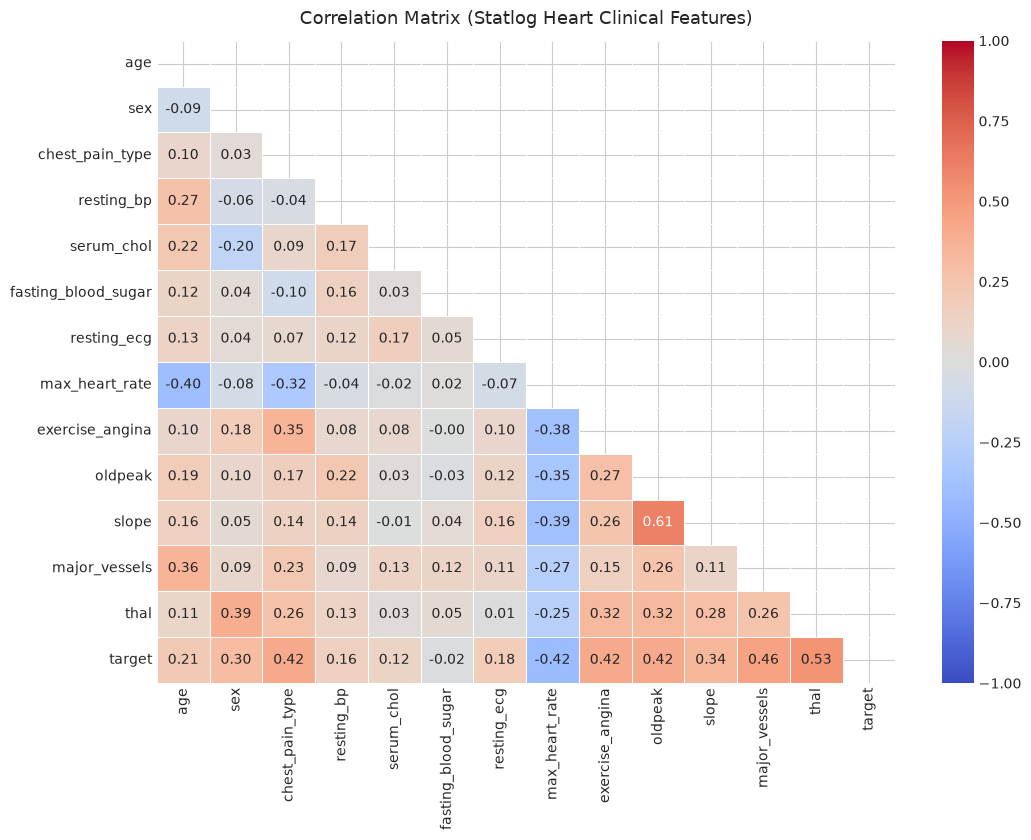

Features Ranked by Correlation with Heart Disease:
thal                   : +0.525
major_vessels          : +0.455
exercise_angina        : +0.419
oldpeak                : +0.418
chest_pain_type        : +0.417
slope                  : +0.338
sex                    : +0.298
age                    : +0.212
resting_ecg            : +0.182
resting_bp             : +0.155
serum_chol             : +0.118
fasting_blood_sugar    : -0.016
max_heart_rate         : -0.419


In [7]:
plt.figure(figsize=(11, 8.5))
corr_matrix = df.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, mask=mask, linewidths=0.5)
plt.title('Correlation Matrix (Statlog Heart Clinical Features)', fontsize=13, pad=12)
plt.show()

# Top correlations with the target
target_corr = corr_matrix['target'].drop('target').sort_values(ascending=False)
print("Features Ranked by Correlation with Heart Disease:")
for feat, val in target_corr.items():
    print(f"{feat:22s} : {val:+.3f}")

## 6. Leak-Free Preprocessing Pipeline

In accordance with rigorous machine learning protocols (and addressing the leakage traps highlighted in the research paper):
1. **Stratified Split (80/20):** Split training and testing sets *before* performing any scaling, encoding, or sampling.
2. **Categorical One-Hot Encoding:** Fit `OneHotEncoder` strictly on `X_train` for nominal variables (`chest_pain_type`, `resting_ecg`, `slope`, `thal`), then transform `X_test`.
3. **Min-Max Scaling:** Scale continuous features to $[0, 1]$ fitting strictly on `X_train`.
4. **Training-Only SMOTE:** Balance classes using SMOTE *strictly on the training split*, preserving pristine testing distribution.

In [8]:
# 1. Stratified Train-Test Split
X = df.drop(columns=['target'])
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Initial Train Split Shape: {X_train.shape} | Targets: Healthy={sum(y_train==0)}, CVD={sum(y_train==1)}")
print(f"Initial Test Split Shape:  {X_test.shape}  | Targets: Healthy={sum(y_test==0)}, CVD={sum(y_test==1)}")

# 2. One-Hot Encoding for Nominal Attributes
nominal_cols = ['chest_pain_type', 'resting_ecg', 'slope', 'thal']
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
ohe_train = ohe.fit_transform(X_train[nominal_cols])
ohe_test = ohe.transform(X_test[nominal_cols])

ohe_cols = ohe.get_feature_names_out(nominal_cols)
df_ohe_tr = pd.DataFrame(ohe_train, columns=ohe_cols, index=X_train.index)
df_ohe_te = pd.DataFrame(ohe_test, columns=ohe_cols, index=X_test.index)

X_train_enc = pd.concat([X_train.drop(columns=nominal_cols), df_ohe_tr], axis=1)
X_test_enc = pd.concat([X_test.drop(columns=nominal_cols), df_ohe_te], axis=1)

# 3. Normalization via MinMaxScaler (Fitted on Train, Applied to Test)
scaler = MinMaxScaler()
feature_names_final = X_train_enc.columns
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_enc), columns=feature_names_final)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_enc), columns=feature_names_final)

# 4. Training-Only SMOTE Oversampling
smote = SMOTE(k_neighbors=5, random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train.reset_index(drop=True))
X_train_final = pd.DataFrame(X_train_resampled, columns=feature_names_final)
y_train_final = pd.Series(y_train_resampled, name='target')

print("\n" + "="*60)
print("FINAL PREPROCESSED DATASET SPECIFICATIONS:")
print("="*60)
print(f"X_train Final Shape: {X_train_final.shape} | Balance: {np.bincount(y_train_final)}")
print(f"X_test Final Shape:  {X_test_scaled.shape}  | Balance: {np.bincount(y_test)}")
print(f"Total Transformed Feature Dimensions: {len(feature_names_final)}")
print("Transformed Columns:", list(feature_names_final))

Initial Train Split Shape: (216, 13) | Targets: Healthy=120, CVD=96
Initial Test Split Shape:  (54, 13)  | Targets: Healthy=30, CVD=24

FINAL PREPROCESSED DATASET SPECIFICATIONS:
X_train Final Shape: (240, 22) | Balance: [120 120]
X_test Final Shape:  (54, 22)  | Balance: [30 24]
Total Transformed Feature Dimensions: 22
Transformed Columns: ['age', 'sex', 'resting_bp', 'serum_chol', 'fasting_blood_sugar', 'max_heart_rate', 'exercise_angina', 'oldpeak', 'major_vessels', 'chest_pain_type_1.0', 'chest_pain_type_2.0', 'chest_pain_type_3.0', 'chest_pain_type_4.0', 'resting_ecg_0.0', 'resting_ecg_1.0', 'resting_ecg_2.0', 'slope_1.0', 'slope_2.0', 'slope_3.0', 'thal_3.0', 'thal_6.0', 'thal_7.0']


## 7. Preprocessed Feature Matrices Inspection
Preview the clean, leak-free normalized training feature matrix.

In [9]:
X_train_final.head(10)

,age,sex,resting_bp,serum_chol,fasting_blood_sugar,max_heart_rate,exercise_angina,oldpeak,major_vessels,chest_pain_type_1.0,...,chest_pain_type_4.0,resting_ecg_0.0,resting_ecg_1.0,resting_ecg_2.0,slope_1.0,slope_2.0,slope_3.0,thal_3.0,thal_6.0,thal_7.0
0,0.270833,0.0,0.245283,0.189498,0.0,0.728972,0.0,0.000000,0.000000,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
1,0.520833,1.0,0.264151,0.365297,0.0,0.196262,1.0,0.516129,0.666667,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
2,0.458333,0.0,0.245283,0.385845,0.0,0.579439,0.0,0.096774,0.000000,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
3,0.833333,0.0,0.433962,0.257991,0.0,0.523364,0.0,0.290323,0.666667,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
4,0.520833,1.0,0.245283,0.301370,0.0,0.485981,0.0,0.064516,0.000000,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
5,0.666667,1.0,0.528302,0.267123,1.0,0.392523,1.0,0.161290,0.000000,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
6,0.520833,1.0,0.150943,0.182648,0.0,0.121495,1.0,0.000000,0.333333,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
7,0.583333,0.0,0.320755,0.404110,0.0,0.598131,0.0,0.000000,0.333333,0.0,...,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
8,0.625000,1.0,0.301887,0.210046,1.0,0.364486,0.0,0.354839,0.333333,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
9,0.500000,1.0,0.339623,0.273973,1.0,0.728972,0.0,0.000000,1.000000,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
